# TF-IDF vs BM25 на корпусе поддержки интернет-магазина

Перед каждой ячейкой с кодом — «🔮 Предскажи». Сначала пишешь предсказание в markdown-ячейке, потом запускаешь.

In [1]:
from retrieval import BM25, TfidfRetriever, tokenize

CORPUS = [
    "Ошибка 0x80070057 при обновлении Windows: как исправить",
    "Процедура возврата средств: оформление заявки и сроки",
    "Возврат возможен только при наличии чека и упаковки",
    "Доставка курьером по Москве занимает один-два рабочих дня",
    "Самовывоз заказа из пункта выдачи: доставка бесплатная, хранение семь дней",
    "Оплата заказа картой онлайн, наличными или через СБП при получении",
    "Если оплата не прошла, деньги вернутся на карту в течение трёх дней",
    "Гарантия на технику один год, ремонт проводится в сервисном центре",
    "Гарантийный ремонт: как сдать товар и сколько ждать",
    (
        "Часто задаваемые вопросы покупателей. Возврат товара надлежащего качества возможен "
        "в течение 14 дней. Возврат товара с дефектом оформляется по гарантии. Возврат техники "
        "требует проверки в сервисном центре. Возврат одежды и обуви принимается при сохранённых "
        "ярлыках. Доставка возвращаемого товара оплачивается покупателем, кроме случаев брака. "
        "Возврат денег на карту занимает до десяти рабочих дней. Возврат наличными производится "
        "в пункте выдачи. Подарочные сертификаты и бонусные баллы не подлежат обмену. Возврат "
        "цифровых товаров невозможен после активации ключа. Если возврат отклонён, напишите в "
        "поддержку, приложите фото и номер заказа, и оператор свяжется с вами в течение суток."
    ),
]
WINDOWS, PROCEDURE, SHORT, LONG = 0, 1, 2, 9

for i, d in enumerate(CORPUS):
    toks = tokenize(d)
    print(f"[{i}] токенов={len(toks):3d}  'возврат'×{toks.count('возврат')}  {d[:70]}")

[0] токенов=  7  'возврат'×0  Ошибка 0x80070057 при обновлении Windows: как исправить
[1] токенов=  6  'возврат'×0  Процедура возврата средств: оформление заявки и сроки
[2] токенов=  7  'возврат'×1  Возврат возможен только при наличии чека и упаковки
[3] токенов=  9  'возврат'×0  Доставка курьером по Москве занимает один-два рабочих дня
[4] токенов= 10  'возврат'×0  Самовывоз заказа из пункта выдачи: доставка бесплатная, хранение семь 
[5] токенов= 10  'возврат'×0  Оплата заказа картой онлайн, наличными или через СБП при получении
[6] токенов= 11  'возврат'×0  Если оплата не прошла, деньги вернутся на карту в течение трёх дней
[7] токенов=  9  'возврат'×0  Гарантия на технику один год, ремонт проводится в сервисном центре
[8] токенов=  7  'возврат'×0  Гарантийный ремонт: как сдать товар и сколько ждать
[9] токенов= 81  'возврат'×8  Часто задаваемые вопросы покупателей. Возврат товара надлежащего качес


In [2]:
def show(name, results):
    print(name)
    for doc_id, score in results:
        print(f"  [{doc_id}] {score:.4f}  {CORPUS[doc_id][:60]}")

tfidf = TfidfRetriever().fit(CORPUS)
bm25 = BM25().fit(CORPUS)

## 1. Редкий точный токен

🔮 **Предскажи:** запрос `"0x80070057"` — какой документ будет топ-1 у TF-IDF и у BM25? Что будет на местах 2–3 и с какими скорами?

**Моё предсказание:** Я не знаю, сколько там всего документов, но, судя по всему, два. Самый первый документ, получается, выведется — это нулевой индекс. На вторых и третьих местах — рандомные документы со скором = 0.

In [3]:
q = "0x80070057"
show("TF-IDF", tfidf.search(q, k=3))
show("BM25", bm25.search(q, k=3))

TF-IDF
  [0] 0.4029  Ошибка 0x80070057 при обновлении Windows: как исправить
  [1] 0.0000  Процедура возврата средств: оформление заявки и сроки
  [2] 0.0000  Возврат возможен только при наличии чека и упаковки
BM25
  [0] 2.6543  Ошибка 0x80070057 при обновлении Windows: как исправить
  [1] 0.0000  Процедура возврата средств: оформление заявки и сроки
  [2] 0.0000  Возврат возможен только при наличии чека и упаковки


## 2. Синонимы и словоформы

🔮 **Предскажи:** запрос `"как вернуть деньги за заказ"` — найдёт ли TF-IDF или BM25 документ [1] «Процедура возврата средств»? Какой у него будет скор? Что окажется в топе вместо него?

**Моё предсказание:** Ни BM25, ни TF-IDF не найдёт первый документ из-за того, что совпавших слов нету. Вместо первого документа в топе окажутся те документы, у которых есть совпадение слов с запросом.

In [4]:
q = "как вернуть деньги за заказ"
show("TF-IDF", tfidf.search(q, k=3))
show("BM25", bm25.search(q, k=3))
print()
print("скор документа [1]:  TF-IDF =", tfidf.transform([q])[0] @ tfidf.doc_matrix_[PROCEDURE],
      "  BM25 =", bm25.score(q)[PROCEDURE])
print("токены запроса:  ", tokenize(q))
print("токены документа:", tokenize(CORPUS[PROCEDURE]))

TF-IDF
  [6] 0.2580  Если оплата не прошла, деньги вернутся на карту в течение тр
  [0] 0.2218  Ошибка 0x80070057 при обновлении Windows: как исправить
  [8] 0.2169  Гарантийный ремонт: как сдать товар и сколько ждать
BM25
  [6] 2.3026  Если оплата не прошла, деньги вернутся на карту в течение тр
  [0] 1.9738  Ошибка 0x80070057 при обновлении Windows: как исправить
  [8] 1.9738  Гарантийный ремонт: как сдать товар и сколько ждать

скор документа [1]:  TF-IDF = 0.0   BM25 = 0.0
токены запроса:   ['как', 'вернуть', 'деньги', 'за', 'заказ']
токены документа: ['процедура', 'возврата', 'средств', 'оформление', 'заявки', 'сроки']


❓ **Почему так и что бы это починило?** (ответ — в чате)

**Мой ответ:** Чтобы починить это, нужно использовать эмбеддинги. Синонимы лемматизация всё равно не спасёт — и не найдёт. А вот «вернуть» — «возврат»: может быть, что-то с этим и получится, если использовать лемматизацию.

## 3. Короткий документ с tf=1 против длинного с tf=8

🔮 **Предскажи:** запрос `"возврат"`, BM25 с `k1=1.5, b=0.75` — кто выше: короткий [2] (tf=1) или длинный [9] (tf=8)? Примерно во сколько раз отличаются скоры?

**Моё предсказание:** Короткий окажется по скору больше, чем длинный текст. Скоры будут отличаться примерно на 30%.

In [5]:
def short_vs_long(s):
    print(f"короткий [2]: {s[SHORT]:.4f}   длинный [9]: {s[LONG]:.4f}   длинный/короткий = {s[LONG] / s[SHORT]:.2f}")

short_vs_long(BM25(k1=1.5, b=0.75).fit(CORPUS).score("возврат"))

короткий [2]: 1.9738   длинный [9]: 2.0898   длинный/короткий = 1.06


🔮 **Предскажи:** то же, но `b=0`. Что изменится и почему?

**Моё предсказание:** - [2]: score = 1 · idf
- [9]: score = 20 / 9.5 · idf

Потому что теперь длина текста не важна → score сильнее больше у того, у кого больше совпавших слов.

In [7]:
short_vs_long(BM25(k1=1.5, b=0).fit(CORPUS).score("возврат"))

короткий [2]: 1.4816   длинный [9]: 3.1192   длинный/короткий = 2.11


🔮 **Предскажи:** то же, но `k1=0` (b=0.75). Что изменится и почему?

**Моё предсказание:** - [2]: score = 1.4816 · (1 / 1)
- [9]: score = 1.4816 · (8 / 8)

Получается, что k «главнее», чем b → score одинаковый, так как теперь не важно количество слов, важно, есть ли оно вообще или нет.

In [8]:
short_vs_long(BM25(k1=0, b=0.75).fit(CORPUS).score("возврат"))

короткий [2]: 1.4816   длинный [9]: 1.4816   длинный/короткий = 1.00


🔮 **Предскажи:** то же у TF-IDF (косинус запроса с документом). Кто выше и почему?

**Моё предсказание:** - [2]: TF = 1, IDF = 1.4816
- [9]: TF = 8, IDF = 1.4816

9-й документ будет в 8 раз больше, потому что множитель TF, соответственно, в 8 раз больше.

In [9]:
short_vs_long(tfidf.transform(["возврат"])[0] @ tfidf.doc_matrix_.T)

короткий [2]: 0.3505   длинный [9]: 0.6172   длинный/короткий = 1.76


## 4. Насыщение по tf

🔮 **Предскажи:** как будет выглядеть вклад одного термина в зависимости от tf (0…20) при `|d| = avgdl`, `idf = 1` для `k1` ∈ {0, 0.5, 1.5, 3}? Какая кривая выше всех при tf=20? Как выглядит кривая при `k1=0`?

**Моё предсказание:** - k1 = 3: в числителе TF · (k + 1), в знаменателе TF + k · (1 − b + b · 1) → числитель примерно в k раз больше.
- k1 = 0: кривая с ростом TF будет прямой = 1 при любых TF.

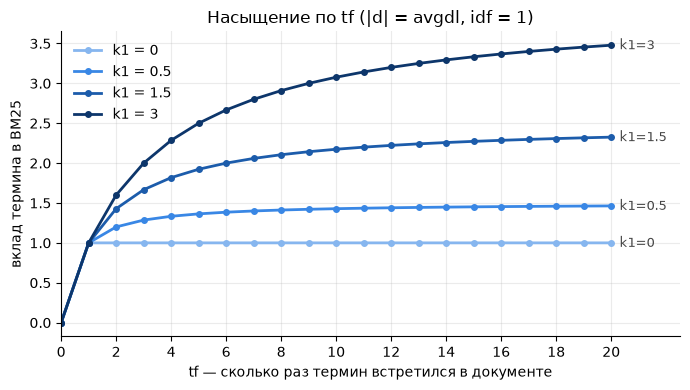

In [10]:
import numpy as np
import matplotlib.pyplot as plt

tf = np.arange(0, 21)
k1_values = [0, 0.5, 1.5, 3]
colors = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # один оттенок: светлее = меньше k1

fig, ax = plt.subplots(figsize=(7, 4))
for k1, c in zip(k1_values, colors):
    # |d| = avgdl -> (1 - b + b * |d| / avgdl) = 1, idf = 1
    contrib = np.divide(tf * (k1 + 1), tf + k1, out=np.zeros(len(tf)), where=tf > 0)
    ax.plot(tf, contrib, color=c, linewidth=2, marker="o", markersize=4, label=f"k1 = {k1}")
    ax.annotate(f"k1={k1}", (tf[-1], contrib[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#444")

ax.set_xlabel("tf — сколько раз термин встретился в документе")
ax.set_ylabel("вклад термина в BM25")
ax.set_title("Насыщение по tf (|d| = avgdl, idf = 1)")
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_xlim(0, 22.5)
ax.set_xticks(range(0, 21, 2))
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

❓ **К какому значению стремится вклад при tf → ∞ и почему?** (ответ — в чате)

**Мой ответ:** В числителе TF · (k + 1), в знаменателе TF + k · (1 − b + b · 1); если вынести TF за скобки, то стремится к k + 1 (при TF → ∞ слагаемое k / TF → 0).